In [1]:
# --- Setup (works locally and in Google Colab) ---
import sys, os
from pathlib import Path
if "google.colab" in sys.modules and not Path("src").exists():
    !git clone https://github.com/ArjunGopal10/privacy-preserving-synthetic-graph-generation.git
    %cd privacy-preserving-synthetic-graph-generation
    !pip install -q -r requirements.txt
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import warnings; warnings.filterwarnings("ignore", category=FutureWarning)
import numpy as np, pandas as pd, networkx as nx, matplotlib.pyplot as plt
from src.visualization.plot_style import apply_style
apply_style(); plt.rcParams["figure.dpi"] = 100
%matplotlib inline

# 02 · Randomized response
$p=1/(1+e^{\varepsilon})$; each of the 561 pairs is flipped independently. One release is $\varepsilon$-**edge**-DP (not node-DP).

In [2]:
from src.graph_generation.graph_loader import load_karate_club
from src.graph_generation.randomized_response import flip_probability, randomized_response_graph
from src.privacy.differential_privacy import expected_release_counts
G = load_karate_club()
rows = [{"epsilon": e, "p": flip_probability(e), **expected_release_counts(561, 78, e)} for e in [0.1, 0.5, 1, 2, 3, 5, 8]]
pd.DataFrame(rows).round(3)

,epsilon,p,kept,deleted,added,total_edges
0,0.1,0.475,40.948,37.052,229.435,270.383
1,0.5,0.378,48.552,29.448,182.352,230.904
2,1.0,0.269,57.023,20.977,129.899,186.921
3,2.0,0.119,68.702,9.298,57.575,126.277
4,3.0,0.047,74.301,3.699,22.907,97.207
5,5.0,0.007,77.478,0.522,3.233,80.711
6,8.0,0.000,77.974,0.026,0.162,78.136


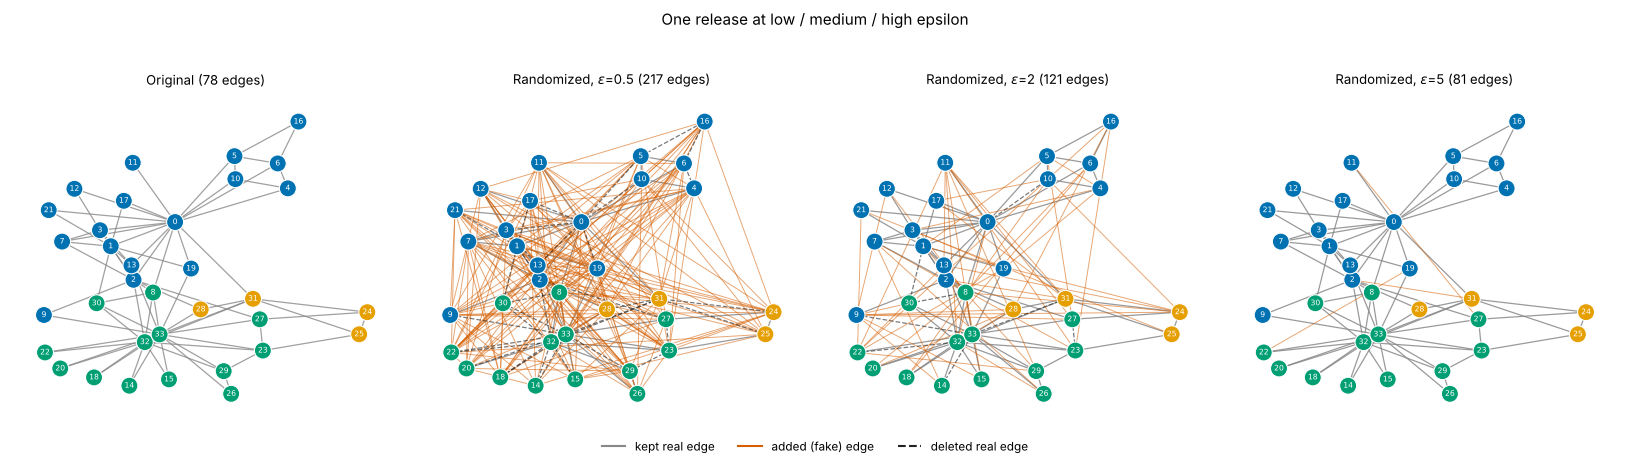

,graph,edges,kept,added,deleted
0,original,78,78,0,0
1,eps=0.5,217,39,178,39
2,eps=2,121,68,53,10
3,eps=5,81,78,3,0


In [3]:
from src.community.community_detection import detect_communities
from src.visualization.graph_visualization import fixed_layout, fig_epsilon_panels
P0 = detect_communities(G, "louvain", seed=42); pos = fixed_layout(G, 42)
rel = {e: randomized_response_graph(G, e, rng=1) for e in (0.5, 2, 5)}
fig, tab = fig_epsilon_panels(G, rel, P0, pos, "One release at low / medium / high epsilon"); plt.show(); tab